# 02 · Platforms: total, then one platform at a time

Section 0 shows all platforms together. Each platform section then repeats the same blocks and always shows the **total over all platforms** next to it (last row in tables, grey in plots).

Order per platform: first rows → missing values and zeros → distributions → time → key numbers → correlations → text and sentiment. Colours are fixed per platform.

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
import eda_utils as eu

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:,.2f}".format); pd.set_option("display.width", 220)
pd.set_option("display.max_columns", None); pd.set_option("display.max_colwidth", 90)

In [2]:
df = eu.load(ROOT)
print(f"{len(df):,} mentions, {df.shape[1]} columns")

12,500 mentions, 19 columns


# All platforms (total)

### 0.1 · First rows (all columns)

,4837,8127,6755
platform,instagram,facebook,youtube
mention_id,83677400315,88841445826,342928107482845184
url,https://www.instagram.com/p/DFma61gMcx9,https://www.facebook.com/775428721255632/posts/1334425982022567,http://www.youtube.com/shorts/TGDXZNDKCGU
created_at,2025-02-02 22:18:02,2025-07-29 21:15:01,2026-07-27 23:39:03
metrics_updated_at,2025-07-18 04:46:30,2025-08-08 02:31:50,2026-08-04 07:14:35
brand,Motorola,eToro,HP
language,pl,en,en
country,PL,NaN,FI
title,Motorola C550 SPECYFIKACJA: - Rok wydania: 2003 - Wyświetlacz: rozdzielczość 96x,WALL STREET MOVE: eToro is diving into tokenized finance - launching 100 U.S.-l,WW2 Piper L-4A “Grasshopper” - Flygfesten 2025 Sunday
content,Motorola C550 SPECYFIKACJA: - Rok wydania: 2003 - Wyświetlacz: rozdzielczość 96x,WALL STREET MOVE: eToro is diving into tokenized finance - launching 100 U.S.-l,Team Grasshoppers flying their Piper L-4A “Grasshopper” planes at Flygfesten 202


### 0.2 · Missing values and zeros

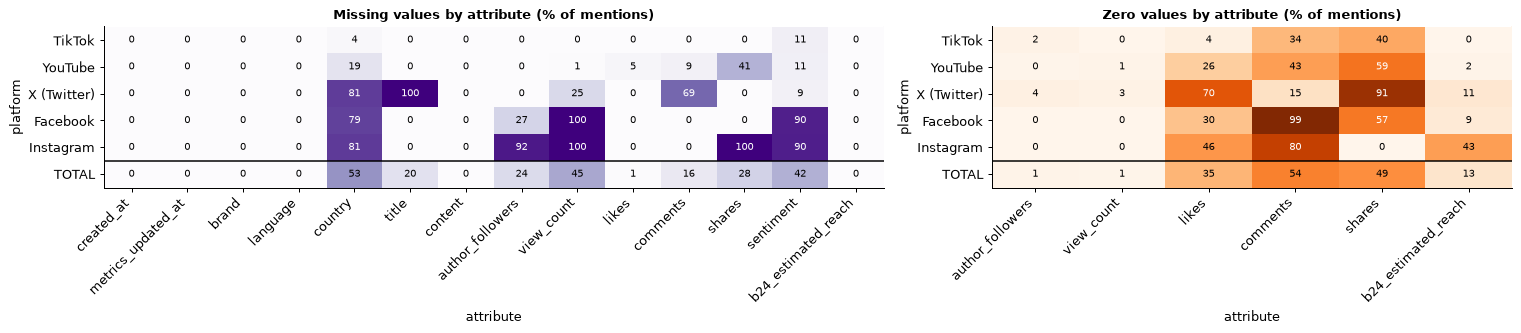

### 0.3 · Key numbers per platform

,mentions,brands,reach median,reach mean / median,reach top-1% share %,views known %,reach == views %,median reach / followers,english %,"median metrics age, days"
TikTok,"2,500.00",266.00,723.00,40.33,62.30,100.00,100.00,0.61,94.04,35.00
YouTube,"2,500.00",273.00,397.00,60.69,72.36,98.92,100.00,0.02,96.80,24.00
X (Twitter),"2,500.00",273.00,141.00,16.10,44.12,74.64,1.88,0.10,97.48,29.00
Facebook,"2,500.00",22.00,"2,200.00",9.08,43.79,0.00,NaN,0.06,71.32,18.00
Instagram,"2,500.00",11.00,20.00,138.25,88.95,0.00,NaN,0.04,64.28,21.00
TOTAL,"12,500.00",348.00,366.00,42.76,66.34,54.71,73.23,0.10,84.78,25.00


### 0.4 · Usable rows: all features of a set present

,TikTok,YouTube,X (Twitter),Facebook,Instagram,TOTAL
followers,2493,2494,2500,1815,205,9507
followers + likes + comments,2493,2252,786,1815,205,7551
+ shares,2493,1462,786,1815,0,6556
+ views (target),2493,2249,767,0,0,5509


### 0.5 · Are partial gaps related to reach? (missing = smaller posts if delta < 0)

missing % median log10 reach, missing median log10 reach, present delta rho (missing, reach) median month, missing median month, present
TikTok      sentiment            11.08                        2.90                        2.85  0.05                 0.02               2025-10               2026-06
            country               3.52                        2.83                        2.86 -0.03                -0.00               2026-06               2026-06
YouTube     likes                 5.08                        1.00                        2.68 -1.68                -0.28               2026-08               2026-06
            comments              9.48                        1.37                        2.72 -1.35                -0.32               2026-08               2026-06
            shares               41.40                        2.18                        2.86 -0.68                -0.27               2026-08               2026-05
            sentiment            10.68                        2.17                        2.66 -0.49                -0.11               2025-09               2026-07
            country              18.84                        2.25                        2.70 -0.45                -0.14               2026-07               2026-06
X (Twitter) view_count           25.36                        1.70                        2.85 -1.14                -0.25               2026-04               2026-06
            comments             68.56                        1.97                        3.15 -1.18                -0.37               2026-06               2026-07
            sentiment             9.44                        2.73                        2.46  0.26                 0.02               2025-08               2026-06
            country              80.96                        2.37                        2.85 -0.48                -0.11               2026-06               2026-06
Facebook    author_followers     27.40                        2.78                        3.58 -0.80                -0.28               2025-04               2026-02
            sentiment            89.56                        3.44                        3.60 -0.16                -0.03               2025-10               2026-08
            country              79.36                        3.51                        3.23  0.28                 0.10               2025-11               2025-11
Instagram   author_followers     91.80                        1.90                        2.40 -0.49                -0.20               2025-10               2026-01
            sentiment            90.12                        1.90                        2.00 -0.10                 0.00               2025-10               2026-08
            country              81.32                        1.90                        2.00 -0.10                -0.02               2025-10               2025-11

### 0.6 · Mentions over time

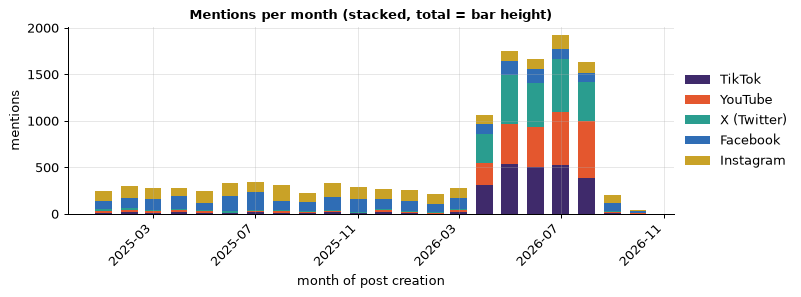

In [3]:
eu.overview(df)

## Read: missing values

- **Structural gaps:** Facebook and Instagram never have views; Instagram almost never has followers (92% missing) and no shares. Only TikTok is complete.
- **Usable rows** (followers + likes + comments): 2,493 TikTok, 2,252 YouTube, 1,815 Facebook, 786 X, 205 Instagram. Rows with views and engagement: none on Facebook or Instagram.
- **Partial gaps are not random.** On YouTube and X a missing like, comment or view count goes with much lower Brand24 reach (delta about -0.7 to -1.7 on log10), so a missing-indicator is a usable feature and a mean would be a wrong fill. Part of each gap also follows collection time (Facebook followers missing for posts before mid 2025, X views mostly before April 2026), so a temporal split must account for it.
- **Decision:** model per platform on complete rows (TikTok, YouTube, X), keep missing-indicators for partial engagement fields, never impute views (the target), treat Facebook and Instagram as transfer targets with wide uncertainty.

# TikTok
2,500 mentions · 266 brands · 2025-01 → 2026-09

### TikTok · 1. First rows (all columns)

,10000,10001,10002
platform,tiktok,tiktok,tiktok
mention_id,347305442168401920,347449668029984768,347366149475921920
url,https://www.tiktok.com/@z_.gab/video/7674519625861778695,https://www.tiktok.com/@adreena197/video/7674518533795106068,https://www.tiktok.com/@_londonthecreator/video/7674518510319439112
created_at,2026-08-15 23:55:54,2026-08-15 23:51:38,2026-08-15 23:51:30
metrics_updated_at,2026-09-14 04:59:09,2026-09-14 05:00:08,2026-09-14 05:00:19
brand,KFC,KFC,KFC
language,en,en,en
country,PH,ID,ZA
title,z_.gab,adreena197,_londonthecreator
content,prom transition pt. 2 (halatang magulo kami) @lianna @Fonz9 @kfc @runkreef @enix,Kfc jambi town square #MisiRasa #SuperBrandGo #SambelMania #SambelinKFC #Sambeli,Stop the elite classism!!!! ‼️ #kfc #kfcghana #tiktokghana #fyp


### TikTok · 2. Missing values and zeros (with total over all platforms)

,created_at,metrics_updated_at,brand,language,country,title,content,author_followers,view_count,likes,comments,shares,sentiment,b24_estimated_reach
missing % · TikTok,0.00,0.00,0.00,0.00,3.50,0.00,0.00,0.30,0.00,0.00,0.00,0.00,11.10,0.00
missing % · TOTAL,0.00,0.00,0.00,0.00,52.80,20.00,0.00,23.90,45.30,1.00,15.60,28.30,42.20,0.00
zeros % · TikTok,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.00,0.40,4.00,33.80,39.80,NaN,0.40
zeros % · TOTAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.30,0.80,35.00,54.20,49.30,NaN,13.10


Partial gaps vs Brand24 reach (delta < 0: missing = smaller posts)

,missing %,"median log10 reach, missing","median log10 reach, present",delta,"rho (missing, reach)","median month, missing","median month, present"
sentiment,11.08,2.90,2.85,0.05,0.02,2025-10,2026-06
country,3.52,2.83,2.86,-0.03,-0.00,2026-06,2026-06


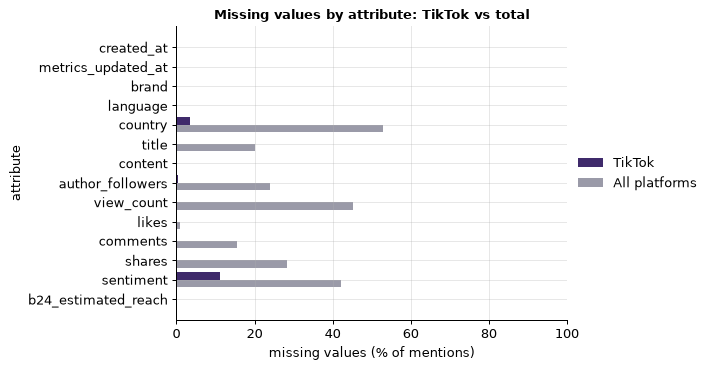

### TikTok · 3. Distributions (log10, positive values only)

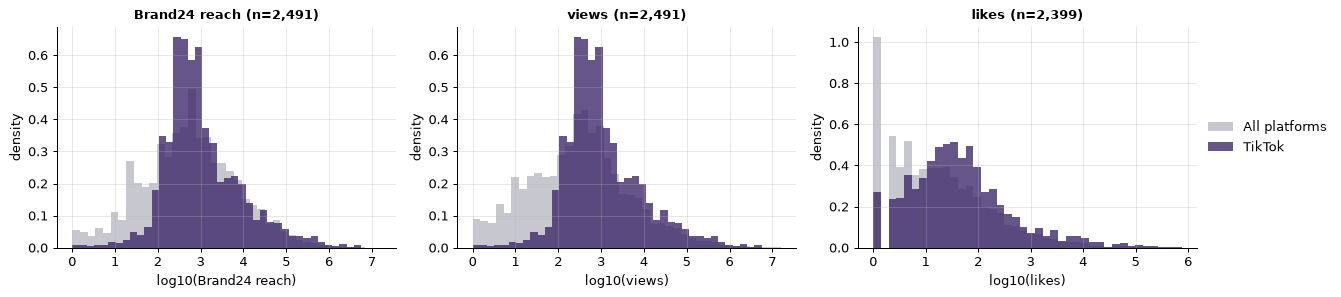

### TikTok · 4. Mentions over time

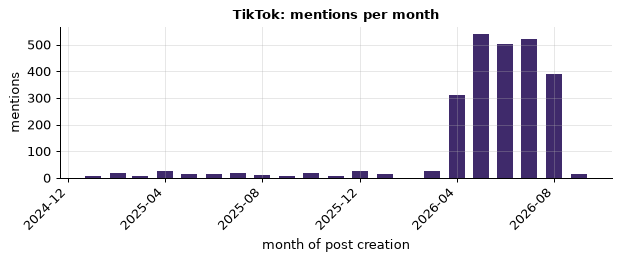

### TikTok · 5. Key numbers (with total over all platforms)

,mentions,brands,reach median,reach mean / median,reach top-1% share %,views known %,reach == views %,median reach / followers,english %,"median metrics age, days"
TikTok,"2,500.00",266.00,723.00,40.33,62.30,100.00,100.00,0.61,94.04,35.00
TOTAL,"12,500.00",348.00,366.00,42.76,66.34,54.71,73.23,0.10,84.78,25.00


### TikTok · 6. Spearman correlations of log1p values

,author_followers,likes,comments,shares
with b24_estimated_reach,0.44,0.87,0.64,0.73
with view_count,0.44,0.87,0.64,0.73


### TikTok · 7. Text, language and sentiment

,english %,empty text %,median text length,duplicate text %
TikTok,94.00,0.00,148.50,2.00
TOTAL,84.80,0.00,279.00,4.00


sentiment,negative,neutral,positive,missing
TikTok,4.60,50.40,33.90,11.10
TOTAL,6.40,37.70,13.60,42.20


brand,KFC,Adidas,Samsung,Priceline,Wyndham
TikTok,37,35,30,30,25


In [4]:
eu.platform_report(df, "tiktok")

# YouTube
2,500 mentions · 273 brands · 2025-01 → 2026-10

### YouTube · 1. First rows (all columns)

,5000,5001,5002
platform,youtube,youtube,youtube
mention_id,338814634163240961,338814511098105856,338814631940259840
url,http://www.youtube.com/watch?v=nw1uDriF5Q4,http://www.youtube.com/shorts/u3rZXnf6esA,http://www.youtube.com/watch?v=jcJBsm-Y9JI
created_at,2026-07-01 23:41:19,2026-07-01 23:30:18,2026-07-01 23:12:14
metrics_updated_at,2026-08-08 23:18:09,2026-07-24 00:08:03,2026-07-24 00:08:28
brand,Samsung,Samsung,Samsung
language,en,en,en
country,PK,IN,BD
title,How to Solve Problem Message not send | Message send problems solution Samsung,Samsung S25 in BIG BILLION DAY Sale Flipkart - Expected Pricing,"M416 Glacier Max diye খেলা হবে , আহো ভাতিজা"
content,In this video I show you How to Solve Problem Message not send Message Not Sent,In this video i told that if it is ok or not to buy samsung galaxy s25 in big bi,I am Back friends ❤ Pubg New Rp with New Update Gameplay #pubgmnextstarprogram #


### YouTube · 2. Missing values and zeros (with total over all platforms)

,created_at,metrics_updated_at,brand,language,country,title,content,author_followers,view_count,likes,comments,shares,sentiment,b24_estimated_reach
missing % · YouTube,0.00,0.00,0.00,0.00,18.80,0.10,0.00,0.20,1.10,5.10,9.50,41.40,10.70,0.00
missing % · TOTAL,0.00,0.00,0.00,0.00,52.80,20.00,0.00,23.90,45.30,1.00,15.60,28.30,42.20,0.00
zeros % · YouTube,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.50,1.30,25.60,43.40,58.60,NaN,1.50
zeros % · TOTAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.30,0.80,35.00,54.20,49.30,NaN,13.10


Partial gaps vs Brand24 reach (delta < 0: missing = smaller posts)

,missing %,"median log10 reach, missing","median log10 reach, present",delta,"rho (missing, reach)","median month, missing","median month, present"
likes,5.08,1.00,2.68,-1.68,-0.28,2026-08,2026-06
comments,9.48,1.37,2.72,-1.35,-0.32,2026-08,2026-06
shares,41.40,2.18,2.86,-0.68,-0.27,2026-08,2026-05
sentiment,10.68,2.17,2.66,-0.49,-0.11,2025-09,2026-07
country,18.84,2.25,2.70,-0.45,-0.14,2026-07,2026-06


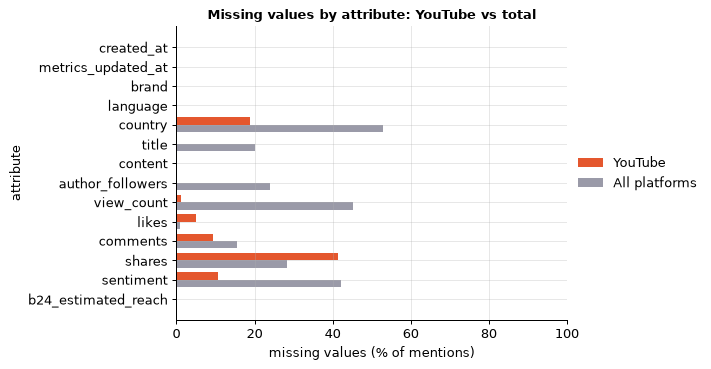

### YouTube · 3. Distributions (log10, positive values only)

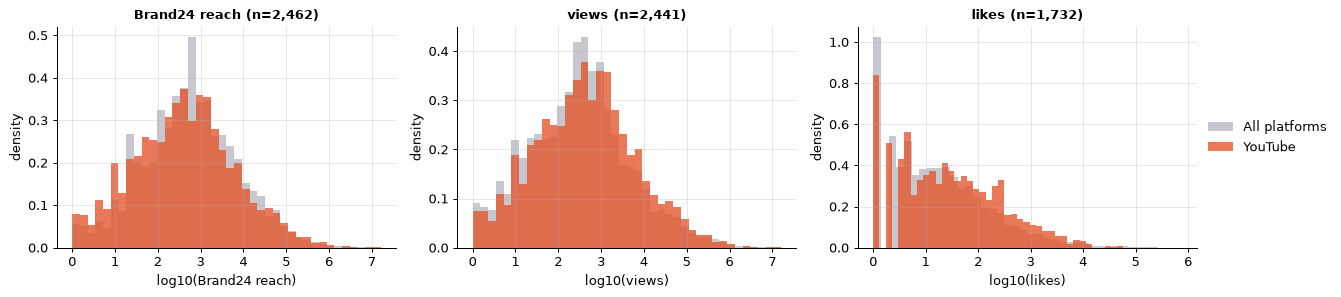

### YouTube · 4. Mentions over time

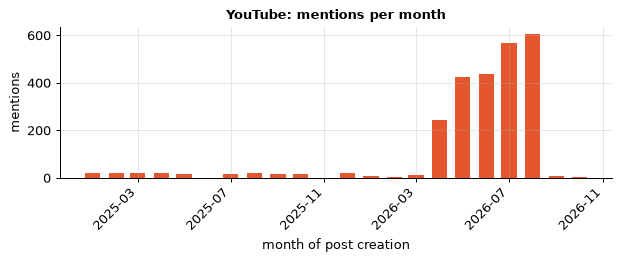

### YouTube · 5. Key numbers (with total over all platforms)

,mentions,brands,reach median,reach mean / median,reach top-1% share %,views known %,reach == views %,median reach / followers,english %,"median metrics age, days"
YouTube,"2,500.00",273.00,397.00,60.69,72.36,98.92,100.00,0.02,96.80,24.00
TOTAL,"12,500.00",348.00,366.00,42.76,66.34,54.71,73.23,0.10,84.78,25.00


### YouTube · 6. Spearman correlations of log1p values

,author_followers,likes,comments,shares
with b24_estimated_reach,0.57,0.63,0.56,NaN
with view_count,0.56,0.63,0.56,NaN


### YouTube · 7. Text, language and sentiment

,english %,empty text %,median text length,duplicate text %
YouTube,96.80,0.00,693.00,5.00
TOTAL,84.80,0.00,279.00,4.00


sentiment,negative,neutral,positive,missing
YouTube,1.60,77.00,10.70,10.70
TOTAL,6.40,37.70,13.60,42.20


brand,Amazon,Asus,HP,New Balance,Guardian Life
YouTube,30,30,30,28,27


In [5]:
eu.platform_report(df, "youtube")

# X (Twitter)
2,500 mentions · 273 brands · 2025-01 → 2026-09

### X (Twitter) · 1. First rows (all columns)

,0,1,2
platform,twitter,twitter,twitter
mention_id,338978424783654912,338978424842375168,338978424892706816
url,http://twitter.com/BestDealsinIND/statuses/2046815673847001116,http://twitter.com/lmanuelmqz/statuses/2046815609380385231,http://twitter.com/monkey_fish24/statuses/2046815568330993854
created_at,2026-04-21 21:57:39,2026-04-21 21:57:23,2026-04-21 21:57:14
metrics_updated_at,2026-07-24 09:41:37,2026-07-24 09:41:35,2026-07-24 09:41:35
brand,Samsung,Samsung,Samsung
language,en,en,en
country,IN,MX,NaN
title,,,
content,"Apply ₹9000 Off Coupon Samsung Galaxy Watch8 Classic (46mm Bluetooth) at Rs.27,","@techdroider Yes, Samsung is the best.",@techdroider Did you consider the fold? It seems many tech reviewers used it for


### X (Twitter) · 2. Missing values and zeros (with total over all platforms)

,created_at,metrics_updated_at,brand,language,country,title,content,author_followers,view_count,likes,comments,shares,sentiment,b24_estimated_reach
missing % · X (Twitter),0.00,0.00,0.00,0.00,81.00,100.00,0.00,0.00,25.40,0.00,68.60,0.00,9.40,0.00
missing % · TOTAL,0.00,0.00,0.00,0.00,52.80,20.00,0.00,23.90,45.30,1.00,15.60,28.30,42.20,0.00
zeros % · X (Twitter),NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.70,2.50,69.60,15.40,90.70,NaN,11.20
zeros % · TOTAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.30,0.80,35.00,54.20,49.30,NaN,13.10


Partial gaps vs Brand24 reach (delta < 0: missing = smaller posts)

,missing %,"median log10 reach, missing","median log10 reach, present",delta,"rho (missing, reach)","median month, missing","median month, present"
view_count,25.36,1.70,2.85,-1.14,-0.25,2026-04,2026-06
comments,68.56,1.97,3.15,-1.18,-0.37,2026-06,2026-07
sentiment,9.44,2.73,2.46,0.26,0.02,2025-08,2026-06
country,80.96,2.37,2.85,-0.48,-0.11,2026-06,2026-06


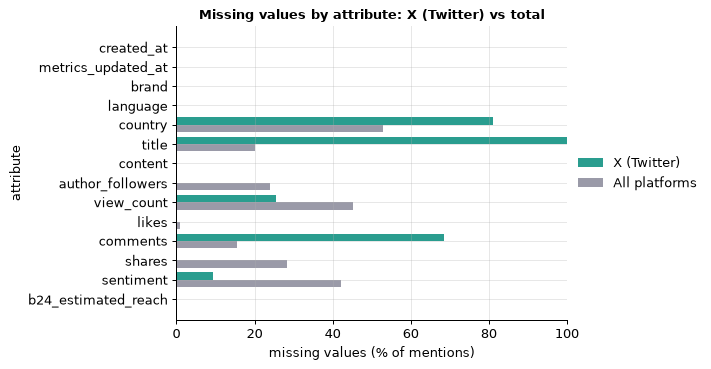

### X (Twitter) · 3. Distributions (log10, positive values only)

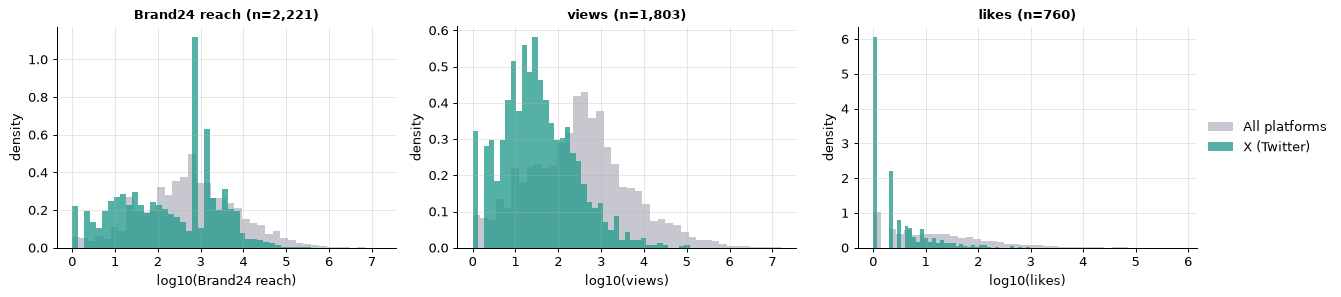

### X (Twitter) · 4. Mentions over time

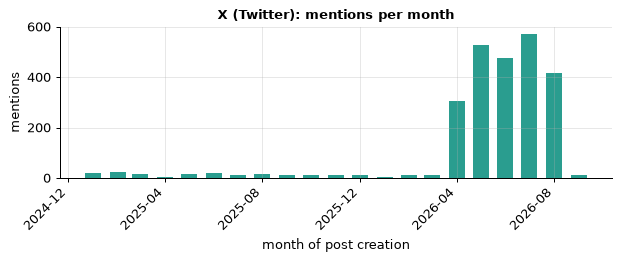

### X (Twitter) · 5. Key numbers (with total over all platforms)

,mentions,brands,reach median,reach mean / median,reach top-1% share %,views known %,reach == views %,median reach / followers,english %,"median metrics age, days"
X (Twitter),"2,500.00",273.00,141.00,16.10,44.12,74.64,1.88,0.10,97.48,29.00
TOTAL,"12,500.00",348.00,366.00,42.76,66.34,54.71,73.23,0.10,84.78,25.00


### X (Twitter) · 6. Spearman correlations of log1p values

,author_followers,likes,comments,shares
with b24_estimated_reach,0.67,0.74,0.69,0.43
with view_count,0.44,0.50,0.45,0.34


### X (Twitter) · 7. Text, language and sentiment

,english %,empty text %,median text length,duplicate text %
X (Twitter),97.50,0.00,211.50,1.70
TOTAL,84.80,0.00,279.00,4.00


sentiment,negative,neutral,positive,missing
X (Twitter),25.30,48.50,16.80,9.40
TOTAL,6.40,37.70,13.60,42.20


brand,Papa Johns,Foot Locker,Lincoln Financial,Kellogg's,Publix
X (Twitter),35,30,29,25,25


In [6]:
eu.platform_report(df, "twitter")

# Facebook
2,500 mentions · 22 brands · 2025-01 → 2026-10

### Facebook · 1. First rows (all columns)

,7500,7501,7502
platform,facebook,facebook,facebook
mention_id,91575549140,307691173881950208,307778652223856640
url,https://www.facebook.com/962690201981336/posts/1370980951152257,https://www.facebook.com/1298885722243112/posts/1569474048517610,https://www.facebook.com/1345244969982237/posts/1870162310823831
created_at,2025-11-08 08:46:40,2026-04-27 12:50:49,2026-04-27 05:17:56
metrics_updated_at,2025-11-27 01:38:22,2026-04-29 01:37:48,2026-04-29 07:23:11
brand,Infosys,Mollie,Mollie
language,en,es,en
country,NaN,NaN,NaN
title,"Rohini Nilekani, often referred to as the female counterpart of Ratan Tata, is o",¡Es tu momento de brillar! Te invitamos a participar en el Concurso de Mejor Man,"Monday Walk Three: fun by the canal! Basil, Freddie, Mollie, Chewie, Vinnie and"
content,"Rohini Nilekani, often referred to as the female counterpart of Ratan Tata, is o",¡Es tu momento de brillar! Te invitamos a participar en el Concurso de Mejor Man,"Monday Walk Three: fun by the canal! Basil, Freddie, Mollie, Chewie, Vinnie and"


### Facebook · 2. Missing values and zeros (with total over all platforms)

,created_at,metrics_updated_at,brand,language,country,title,content,author_followers,view_count,likes,comments,shares,sentiment,b24_estimated_reach
missing % · Facebook,0.00,0.00,0.00,0.00,79.40,0.00,0.00,27.40,100.00,0.00,0.00,0.00,89.60,0.00
missing % · TOTAL,0.00,0.00,0.00,0.00,52.80,20.00,0.00,23.90,45.30,1.00,15.60,28.30,42.20,0.00
zeros % · Facebook,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.20,0.00,29.80,98.80,57.40,NaN,8.90
zeros % · TOTAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.30,0.80,35.00,54.20,49.30,NaN,13.10


Partial gaps vs Brand24 reach (delta < 0: missing = smaller posts)

,missing %,"median log10 reach, missing","median log10 reach, present",delta,"rho (missing, reach)","median month, missing","median month, present"
author_followers,27.40,2.78,3.58,-0.80,-0.28,2025-04,2026-02
sentiment,89.56,3.44,3.60,-0.16,-0.03,2025-10,2026-08
country,79.36,3.51,3.23,0.28,0.10,2025-11,2025-11


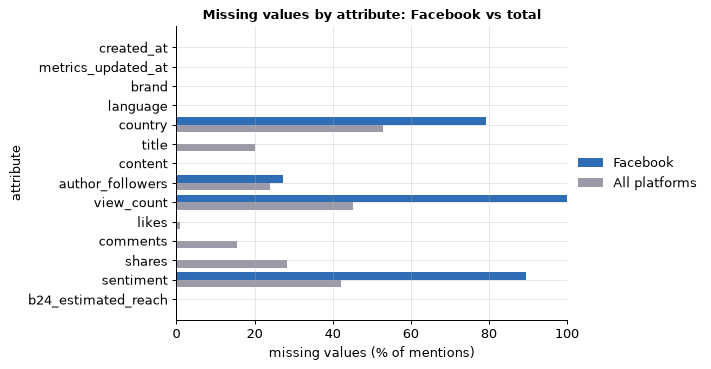

### Facebook · 3. Distributions (log10, positive values only)

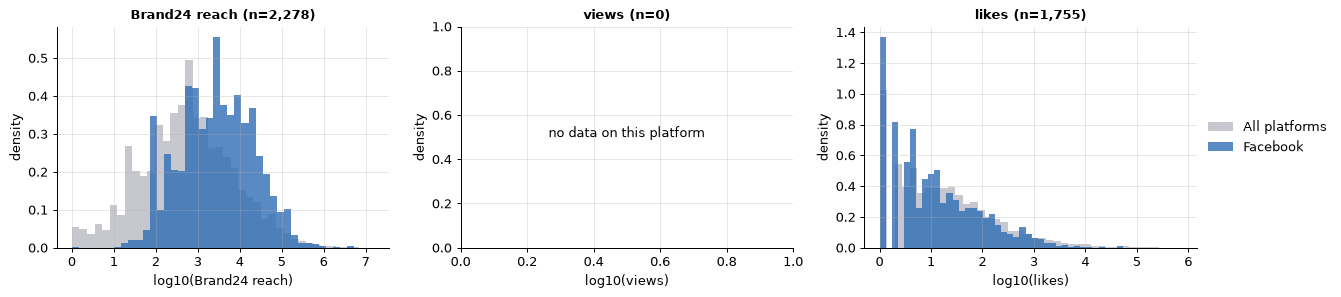

### Facebook · 4. Mentions over time

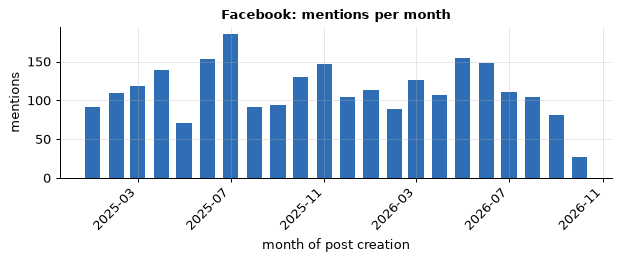

### Facebook · 5. Key numbers (with total over all platforms)

,mentions,brands,reach median,reach mean / median,reach top-1% share %,views known %,reach == views %,median reach / followers,english %,"median metrics age, days"
Facebook,"2,500.00",22.00,"2,200.00",9.08,43.79,0.00,NaN,0.06,71.32,18.00
TOTAL,"12,500.00",348.00,366.00,42.76,66.34,54.71,73.23,0.10,84.78,25.00


### Facebook · 6. Spearman correlations of log1p values

,author_followers,view_count,likes,comments,shares
with b24_estimated_reach,0.93,NaN,0.68,0.06,0.53


### Facebook · 7. Text, language and sentiment

,english %,empty text %,median text length,duplicate text %
Facebook,71.30,0.00,373.00,5.70
TOTAL,84.80,0.00,279.00,4.00


sentiment,missing,neutral,positive,negative
Facebook,89.60,6.70,3.20,0.60
TOTAL,42.20,37.70,13.60,6.40


brand,Coinbase,Adidas,The North Face,Monster Energy,eToro
Facebook,263,230,218,217,178


In [7]:
eu.platform_report(df, "facebook")

# Instagram
2,500 mentions · 11 brands · 2025-01 → 2026-10

### Instagram · 1. First rows (all columns)

,2500,2501,2502
platform,instagram,instagram,instagram
mention_id,273341427064332288,85568276579,85567788431
url,https://www.instagram.com/p/DT4igv5klBW,https://www.instagram.com/p/DITAfQty_BL,https://www.instagram.com/reel/DITAHqvS9lT
created_at,2026-01-23 22:30:38,2025-04-10 23:55:41,2025-04-10 23:53:48
metrics_updated_at,2026-02-07 22:54:22,2025-07-18 03:15:00,2025-07-18 03:15:00
brand,Puma,PayPal,PayPal
language,sk,en,es
country,SK,NaN,NaN
title,Toto chceš mať v šatníku ⁠ ⁠ Nová kolekcia vznikla pri štarte viacročného globál,Let s see how the algorithm treats this post what happens if we mix them both? 1,Gracias a nuestra amplia experiencia y la calidad de nuestros materiales capilar
content,Toto chceš mať v šatníku ⁠ ⁠ Nová kolekcia vznikla pri štarte viacročného globál,Let s see how the algorithm treats this post what happens if we mix them both? 1,Gracias a nuestra amplia experiencia y la calidad de nuestros materiales capilar


### Instagram · 2. Missing values and zeros (with total over all platforms)

,created_at,metrics_updated_at,brand,language,country,title,content,author_followers,view_count,likes,comments,shares,sentiment,b24_estimated_reach
missing % · Instagram,0.00,0.00,0.00,0.00,81.30,0.00,0.00,91.80,100.00,0.00,0.00,100.00,90.10,0.00
missing % · TOTAL,0.00,0.00,0.00,0.00,52.80,20.00,0.00,23.90,45.30,1.00,15.60,28.30,42.20,0.00
zeros % · Instagram,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,0.00,46.10,79.90,0.00,NaN,43.40
zeros % · TOTAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.30,0.80,35.00,54.20,49.30,NaN,13.10


Partial gaps vs Brand24 reach (delta < 0: missing = smaller posts)

,missing %,"median log10 reach, missing","median log10 reach, present",delta,"rho (missing, reach)","median month, missing","median month, present"
author_followers,91.80,1.90,2.40,-0.49,-0.20,2025-10,2026-01
sentiment,90.12,1.90,2.00,-0.10,0.00,2025-10,2026-08
country,81.32,1.90,2.00,-0.10,-0.02,2025-10,2025-11


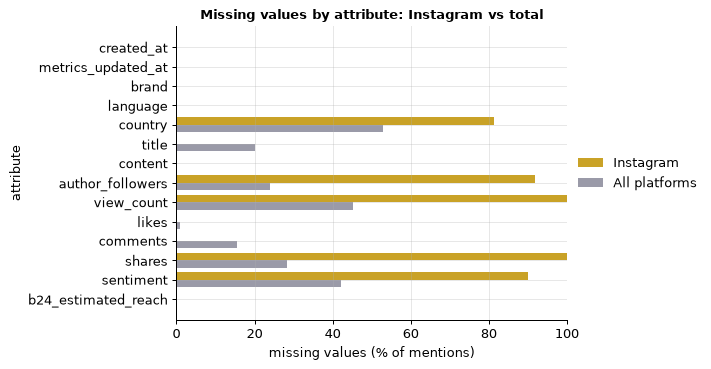

### Instagram · 3. Distributions (log10, positive values only)

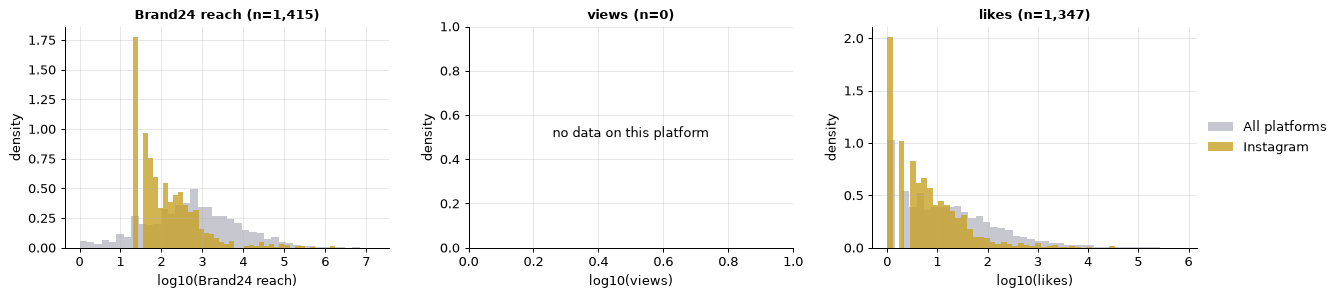

### Instagram · 4. Mentions over time

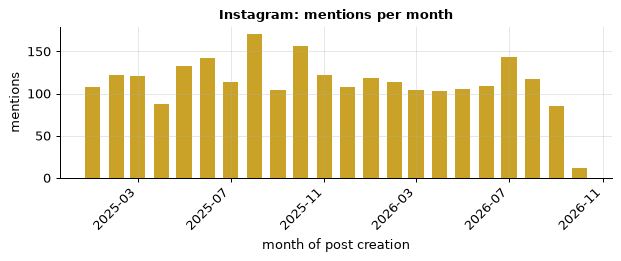

### Instagram · 5. Key numbers (with total over all platforms)

,mentions,brands,reach median,reach mean / median,reach top-1% share %,views known %,reach == views %,median reach / followers,english %,"median metrics age, days"
Instagram,"2,500.00",11.00,20.00,138.25,88.95,0.00,NaN,0.04,64.28,21.00
TOTAL,"12,500.00",348.00,366.00,42.76,66.34,54.71,73.23,0.10,84.78,25.00


### Instagram · 6. Spearman correlations of log1p values

,author_followers,view_count,likes,comments,shares
with b24_estimated_reach,0.54,NaN,0.97,0.59,NaN


### Instagram · 7. Text, language and sentiment

,english %,empty text %,median text length,duplicate text %
Instagram,64.30,0.00,398.50,5.60
TOTAL,84.80,0.00,279.00,4.00


sentiment,missing,neutral,positive,negative
Instagram,90.10,6.10,3.60,0.20
TOTAL,42.20,37.70,13.60,6.40


brand,Adidas,eToro,Mollie,The North Face,Avanza
Instagram,330,319,297,275,265


In [8]:
eu.platform_report(df, "instagram")